# TP3: ¿El cliente tiene la señal de la fibra en riesgo?

**Aprendizaje Automático y Grandes Datos, UNRaf, 2026. Objetivo 14.**

**Problema.** Para cada equipo (ONT) online, predecir si la potencia óptica que le llega está **en riesgo**: por debajo
de −25 dBm. Es **clasificación binaria**. La sensibilidad mínima del equipo (clase B+) es −27 dBm, así que −25 deja 2 dB
de margen antes de que el cliente se quede sin servicio.

**La condición clave: sin mirar su propia señal.** El modelo usa lo que ya se sabe **antes** de medir al cliente: dónde
está, qué equipo tiene y cómo les llega la señal a sus vecinos de puerto.

**Relevancia.**
- Elegir el puerto de cada alta nueva para que el cliente no quede al límite.
- Anticiparse a los reclamos.
- Saber si el problema está en la fibra o en el módem.

**Origen en el TP1.** En el TP1 detectamos una fuga de datos (respaldo R3): usar la señal del propio equipo para predecir
su estado "acierta" sin aprender nada. Esta pregunta la evita a propósito.

**Datos.** El inventario del TP1 cruzado con el listado de la OLT que entregó la empresa el 29/10/2026. La cátedra
confirmó que el TP3 puede usar este cruce.

**Organización.** La lógica vive en `src/tp3_clasificacion.py`; este notebook la llama paso a paso. Hay secciones aparte
para el **plus de ensamble** (sección 13) y de **clustering** (sección 14). Todas las cifras van a `results/metrics.json`.

In [1]:
# Configuración: rutas, semillas y librerías. El notebook se puede abrir desde notebooks/ o desde la raíz.
import os, sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import tp3_clasificacion as t3        # funciones del TP3 (mismo código que corre run_all.py)
pd.set_option("display.width", 220, "display.max_columns", 30, "display.precision", 3)
print("Semilla:", t3.SEED)

Semilla: 42


## 1. Datos y distribución de clases

Se parte de las ONTs de la Fase 1 cruzadas con el listado de la OLT por Localidad + Slot + PON + ID. Quedan los equipos
**online** que están en los dos listados y tienen una lectura de potencia válida.

In [2]:
# Dataset del objetivo 14 y distribución de la clase.
d = t3.cargar_datos()
print(f"{len(d)} equipos de {d[t3.GRUPO].nunique()} PON")
dist = d[t3.OBJETIVO].value_counts().rename(index={0: "sin riesgo", 1: "en riesgo"}).to_frame("equipos")
dist["%"] = (dist["equipos"] / len(d) * 100).round(1)
display(dist)
print(f"Desbalance: 1 en riesgo cada {(d[t3.OBJETIVO] == 0).sum() / d[t3.OBJETIVO].sum():.1f} sin riesgo.")
print(f"Un clasificador que dice siempre 'sin riesgo' tendría accuracy {1 - d[t3.OBJETIVO].mean():.3f} y no detectaría a nadie.")

4872 equipos de 300 PON


,equipos,%
en_riesgo,,
sin riesgo,4324,88.8
en riesgo,548,11.2


Desbalance: 1 en riesgo cada 7.9 sin riesgo.
Un clasificador que dice siempre 'sin riesgo' tendría accuracy 0.888 y no detectaría a nadie.


**Impacto del desbalance.** Con 11 % de clase positiva, la **accuracy engaña**: decir siempre "sin riesgo" da 89 %. Por
eso se miran recall, precisión y F1 de la clase "en riesgo", la accuracy balanceada, el Kappa de Cohen y las áreas ROC y
precisión-recall (PR-AUC).

**Estrategia contra el desbalance.**
- `class_weight="balanced"` en los modelos que lo permiten.
- En KNN, Naive Bayes y Gradient Boosting, que no lo permiten, el umbral de decisión se elige en validación cruzada.

## 2. Variables de entrada

| Variable | ¿Entra? | Por qué |
|---|---|---|
| `Localidad`, `slot_n`, `pon_n` | Sí | Ubicación en la red: cada localidad tiene su planta de fibra |
| `ID`, `id_rel`, `onts_pon` | Sí | Posición del equipo en su puerto y cuántos equipos comparten la fibra (más equipos = más división de la señal) |
| `Distancia_m` | Sí | Más fibra, más atenuación |
| `vec_rxp` | Sí | Señal media de los **otros** equipos online del mismo PON. Ya está medida cuando se instala un cliente nuevo |
| `Modelo_canonico`, `Puertos_LAN`, `WiFi_Tecnologia` | Sí | Para probar si el equipo influye (hipótesis: casi no) |
| `fw_generacion`, `fw_fuera_estandar` | Sí | Ídem con el firmware |
| `RXP_dBm`, `TXP_dBm`, `Estado`, `Nivel_senal` del propio equipo | **No (fuga)** | Son la respuesta o se calculan a partir de ella: la misma fuga del TP1 |
| `Modulo_Optico`, `Puertos_POTS`, `CATV` | No | Dependen 100 % del modelo: repetirían `Modelo_canonico` |
| SN, IP | No | Identificadores (y datos sensibles de la empresa) |

## 3. Partición: estratificada y agrupada por PON

Los equipos de un mismo PON comparten la fibra. Si un PON quedara repartido entre entrenamiento y prueba, el modelo
"vería" en la prueba la misma fibra que aprendió, y el resultado sería optimista.

Por eso se usa `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` con `groups=pon_key`:
- **Prueba:** una de las 5 particiones (≈ 20 %), estratificada y separada por PON. Se usa **una sola vez**, al final.
- **Validación cruzada:** la misma estrategia, sobre el 80 % restante, para elegir hiperparámetros y modelo.

In [3]:
# Partición y chequeos: ningún PON en los dos lados y la misma proporción de clase.
train, test = t3.particion(d)
cols = t3.CATEGORICAS + t3.NUMERICAS
assert not set(cols) & set(t3.PROHIBIDAS), "fuga: hay una variable prohibida entre las entradas"
Xtr, ytr, gtr = train[cols], train[t3.OBJETIVO], train[t3.GRUPO]
Xte, yte = test[cols], test[t3.OBJETIVO]
print(f"Entrenamiento: {len(train)} equipos de {gtr.nunique()} PON, {ytr.mean():.1%} en riesgo")
print(f"Prueba:        {len(test)} equipos de {test[t3.GRUPO].nunique()} PON, {yte.mean():.1%} en riesgo")
print("PON compartidos entre entrenamiento y prueba:", len(set(gtr) & set(test[t3.GRUPO])))
print("Nulos en vec_rxp (PON con un solo equipo online), se imputan en el pipeline:", int(d["vec_rxp"].isna().sum()))

Entrenamiento: 3899 equipos de 237 PON, 11.3% en riesgo
Prueba:        973 equipos de 63 PON, 11.1% en riesgo
PON compartidos entre entrenamiento y prueba: 0
Nulos en vec_rxp (PON con un solo equipo online), se imputan en el pipeline: 8


## 4. Preprocesamiento en un Pipeline

`ColumnTransformer` con:
- `OneHotEncoder(handle_unknown="ignore")` para las categóricas. Es denso, porque Naive Bayes no acepta matrices dispersas.
- Mediana + `StandardScaler` para las numéricas. El escalado es necesario para la Regresión Logística (regularización) y
  para KNN (distancias).

Todo va dentro de un `Pipeline`, así nada se ajusta con datos de validación o de prueba.

## 5. Clasificadores e hiperparámetros

- **Línea base:** Regresión Logística (la que recomienda la consigna).
- **Individuales:** Árbol de Decisión, KNN y Naive Bayes.
- **Referencias:**
  - `DummyClassifier(strategy="prior")`.
  - La **regla de los vecinos** (sección 7): sin ML, no es un clasificador más.

Cada uno se ajusta con `GridSearchCV` y la misma validación agrupada, eligiendo por PR-AUC: es la métrica que mejor
refleja cuánto se detecta la clase chica.

In [4]:
# Espacio de búsqueda y justificación de cada modelo.
display(pd.DataFrame([{"modelo": n, "grilla": str({k.replace('modelo__', ''): v for k, v in g.items()}) or "(sin hiperparámetros)",
                       "umbral elegido en CV": "sí" if u else "no (0,5)", "justificación": j}
                      for n, (_, g, u, j) in t3.HIPERPARAMETROS.items()]).style.hide(axis="index"))

modelo,grilla,umbral elegido en CV,justificación
Dummy (prior),{},"no (0,5)",Predice la proporción de la clase (11 %) para todos: siempre dice 'sin riesgo'. Es el piso.
Regresión Logística,"{'C': [0.01, 0.1, 1, 10]}","no (0,5)","Línea base de la consigna. C es la inversa de la regularización: con ~50 columnas one-hot conviene probar de mucha (0,01) a poca (10). class_weight='balanced' compensa el 11 % de clase positiva."
Árbol de Decisión,"{'max_depth': [3, 5, 8, None], 'min_samples_leaf': [10, 50]}","no (0,5)","Interpretable (se puede dibujar). max_depth y min_samples_leaf limitan la memorización: sin límite, el árbol aprende cada equipo de entrenamiento."
KNN,"{'n_neighbors': [15, 31, 51, 101], 'weights': ['uniform', 'distance']}",sí,Clasifica según los k equipos más parecidos. k chico memoriza ruido; k grande suaviza. No tiene class_weight: el umbral de decisión se elige en validación cruzada.
Naive Bayes,"{'var_smoothing': [1e-09, 1e-06, 0.001, 0.1]}",sí,Supone variables independientes y normales (one-hot denso). var_smoothing estabiliza las varianzas de las columnas binarias. Sin class_weight: umbral elegido en validación cruzada.
Random Forest,"{'min_samples_leaf': [1, 5, 20], 'max_depth': [None, 10]}","no (0,5)","Ensamble por bagging: 300 árboles sobre muestras distintas, que votan. Hojas mínimas y profundidad limitan la memorización."
Gradient Boosting,"{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]}",sí,"Ensamble por boosting: 200 árboles chicos en secuencia, cada uno corrige al anterior. Sin class_weight: umbral elegido en validación cruzada."


## 6. Entrenamiento de los clasificadores individuales

In [5]:
# GridSearchCV de la referencia y de los 4 clasificadores individuales.
busquedas = {n: t3.entrenar(n, Xtr, ytr, gtr) for n in ["Dummy (prior)"] + t3.INDIVIDUALES}
for n, gs in busquedas.items():
    print(f"{n:20s} mejores: {gs.best_params_ or '-'} | PR-AUC CV {gs.best_score_:.3f} | umbral {gs.umbral_:.3f}")

Dummy (prior)        mejores: - | PR-AUC CV 0.113 | umbral 0.500
Regresión Logística  mejores: {'modelo__C': 0.01} | PR-AUC CV 0.322 | umbral 0.500
Árbol de Decisión    mejores: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 50} | PR-AUC CV 0.301 | umbral 0.500
KNN                  mejores: {'modelo__n_neighbors': 101, 'modelo__weights': 'distance'} | PR-AUC CV 0.299 | umbral 0.167
Naive Bayes          mejores: {'modelo__var_smoothing': 0.1} | PR-AUC CV 0.283 | umbral 0.194


## 7. Segunda referencia: la regla de los vecinos (sin ML)

Se ordena a los clientes por la señal media de sus vecinos de PON (`vec_rxp`, sin contar al propio equipo): cuanto más
débil, más riesgo. Se usa `−vec_rxp` como puntaje y se mide ROC-AUC y PR-AUC en la misma prueba. Si un modelo no le gana,
el ML no agrega nada sobre mirar a los vecinos.

In [6]:
# ROC-AUC y PR-AUC de la regla de los vecinos.
vecinos = t3.regla_vecinos(train, test)
display(pd.DataFrame(vecinos).T.round(3))

,ROC_AUC,PR_AUC
entrenamiento,0.732,0.352
prueba,0.710,0.397


## 8. Tabla comparativa (entrenamiento, validación cruzada y prueba)

In [7]:
# Métricas de los individuales + referencias. El clasificador se elige por PR-AUC de validación cruzada.
tabla_ind = t3.tabla_metricas(busquedas, Xtr, ytr, gtr, Xte, yte, vecinos)
display(tabla_ind.drop(columns=["tipo", "segundos_busqueda"]).round(3))
mejor = t3.elegir_mejor(tabla_ind)
print("Clasificador elegido (mayor PR-AUC de validación cruzada entre los individuales):", mejor)

,modelo,hiperparametros,umbral,conjunto,accuracy,accuracy_balanceada,precision,recall,F1,F1_ponderado,kappa,ROC_AUC,PR_AUC
0,Dummy (prior),-,0.500,entrenamiento,0.887,0.500,0.000,0.000,0.000,0.834,0.000,0.500,0.113
1,Dummy (prior),-,0.500,validación cruzada (media),0.887,0.500,0.000,0.000,0.000,0.834,0.000,0.500,0.113
2,Dummy (prior),-,0.500,validación cruzada (desvío),0.003,0.000,0.000,0.000,0.000,0.004,0.000,0.000,0.003
3,Dummy (prior),-,0.500,prueba,0.889,0.500,0.000,0.000,0.000,0.837,0.000,0.500,0.111
4,Regresión Logística,{'C': 0.01},0.500,entrenamiento,0.741,0.687,0.244,0.616,0.349,0.783,0.224,0.741,0.342
5,Regresión Logística,{'C': 0.01},0.500,validación cruzada (media),0.739,0.683,0.263,0.611,0.358,0.781,0.235,0.718,0.322
6,Regresión Logística,{'C': 0.01},0.500,validación cruzada (desvío),0.078,0.045,0.097,0.080,0.081,0.057,0.109,0.044,0.114
7,Regresión Logística,{'C': 0.01},0.500,prueba,0.769,0.675,0.253,0.556,0.348,0.803,0.230,0.698,0.389
8,Árbol de Decisión,"{'max_depth': 8, 'min_samples_leaf': 50}",0.500,entrenamiento,0.777,0.757,0.300,0.732,0.426,0.813,0.316,0.838,0.429
9,Árbol de Decisión,"{'max_depth': 8, 'min_samples_leaf': 50}",0.500,validación cruzada (media),0.688,0.638,0.203,0.572,0.299,0.742,0.157,0.669,0.301


Clasificador elegido (mayor PR-AUC de validación cruzada entre los individuales): Regresión Logística


In [8]:
# classification_report en prueba (por clase y promedio ponderado) de cada modelo.
reportes_ind, matrices_ind = t3.reportes_y_matrices(busquedas, Xtr, ytr, Xte, yte)
display(reportes_ind[reportes_ind["conjunto"] == "prueba"].drop(columns="conjunto").round(3))

,modelo,clase,precision,recall,f1-score,support
4,Dummy (prior),sin riesgo,0.889,1.000,0.941,865.0
5,Dummy (prior),en riesgo,0.000,0.000,0.000,108.0
6,Dummy (prior),macro avg,0.445,0.500,0.471,973.0
7,Dummy (prior),weighted avg,0.790,0.889,0.837,973.0
12,Regresión Logística,sin riesgo,0.935,0.795,0.859,865.0
13,Regresión Logística,en riesgo,0.253,0.556,0.348,108.0
14,Regresión Logística,macro avg,0.594,0.675,0.604,973.0
15,Regresión Logística,weighted avg,0.859,0.769,0.803,973.0
20,Árbol de Decisión,sin riesgo,0.928,0.779,0.847,865.0
21,Árbol de Decisión,en riesgo,0.227,0.519,0.315,108.0


## 9. Matrices de confusión

Una por modelo, en prueba, con cantidades y lo que significa cada casilla. Los errores que más importan acá son los
**clientes en riesgo que el modelo no detectó** (abajo a la izquierda): terminan en reclamo.

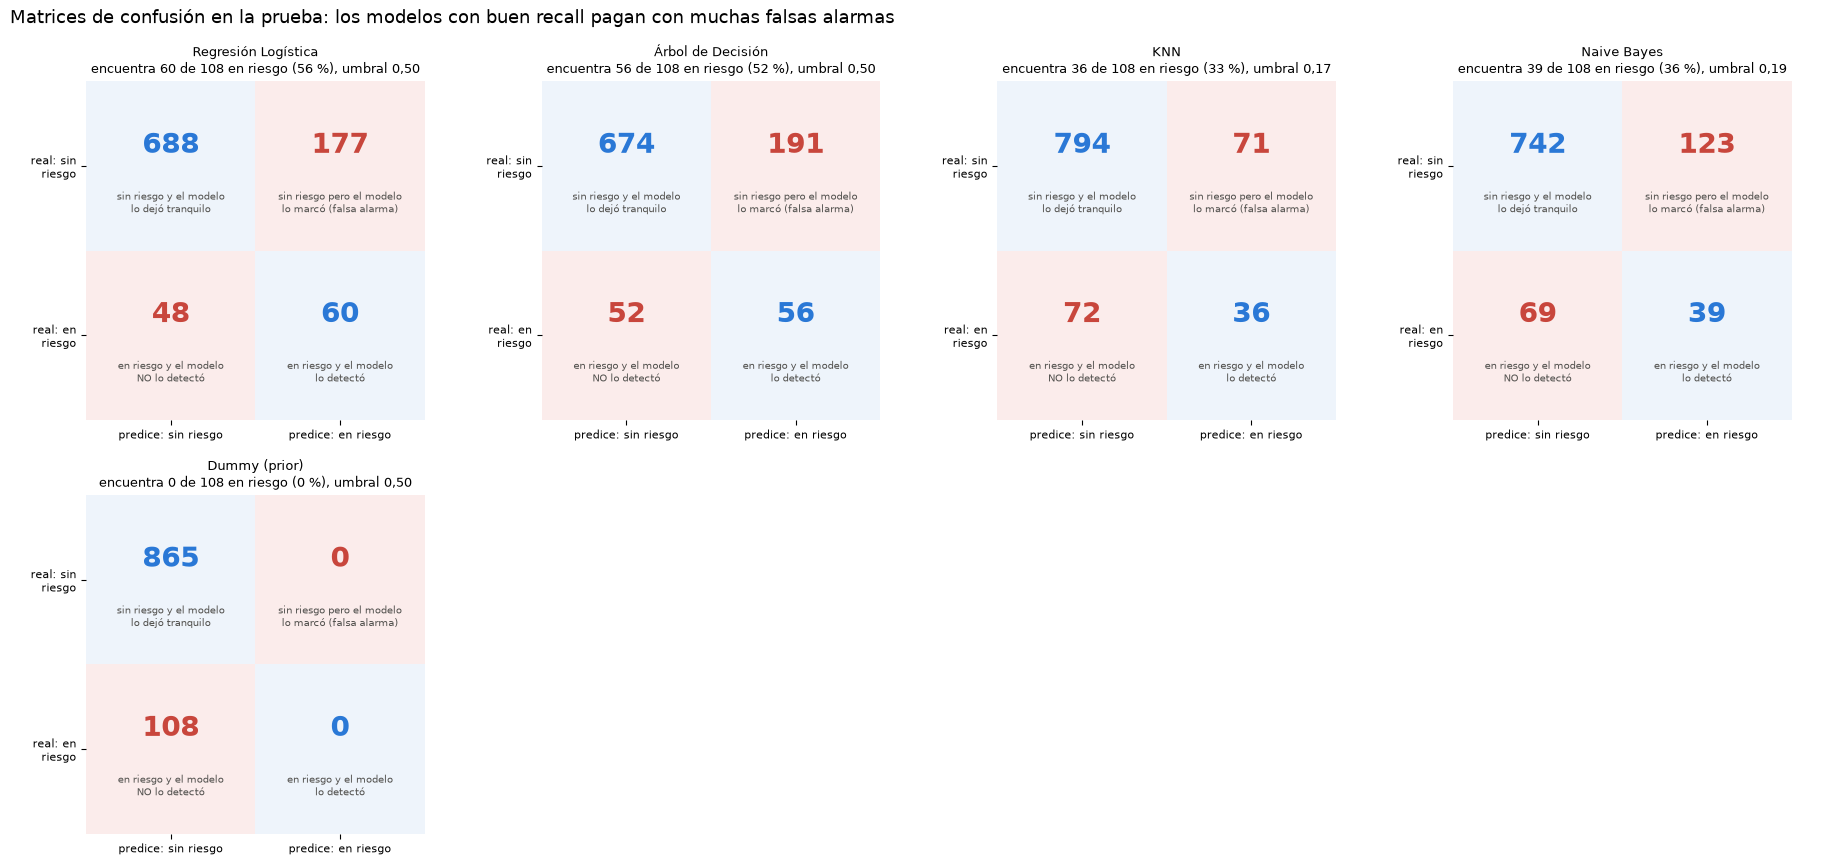

In [9]:
# Matrices de confusión de los individuales y del Dummy.
t3.fig_matrices(matrices_ind, t3.INDIVIDUALES + ["Dummy (prior)"], {n: gs.umbral_ for n, gs in busquedas.items()});

## 10. ¿Sobreajuste o subajuste?

Convención del equipo, sobre ROC-AUC (no depende del umbral):
- **Subajuste:** ROC-AUC de entrenamiento menor que 0,68. No separa ni lo que ya vio.
- **Sobreajuste:** la ROC-AUC de entrenamiento supera a la de validación cruzada **o** a la de prueba por más de 0,10.

In [10]:
# Diagnóstico de los individuales.
diag_ind = t3.diagnostico(tabla_ind).dropna()
display(diag_ind.round(3))

,modelo,ROC_entrenamiento,ROC_cv,ROC_prueba,brecha_entrenamiento_cv,brecha_entrenamiento_prueba,diagnostico
0,Dummy (prior),0.500,0.500,0.500,0.000,0.000,subajuste: sesgo alto (no separa ni el entrena...
1,Regresión Logística,0.741,0.718,0.698,0.023,0.043,ajuste razonable: sesgo y varianza equilibrados
2,Árbol de Decisión,0.838,0.669,0.710,0.169,0.128,sobreajuste: varianza alta (memoriza el entren...
3,KNN,1.000,0.688,0.661,0.312,0.339,sobreajuste: varianza alta (memoriza el entren...
4,Naive Bayes,0.727,0.707,0.670,0.020,0.056,ajuste razonable: sesgo y varianza equilibrados


## 11. Búsqueda de hiperparámetros, umbral de decisión e importancia de variables

In [11]:
# Espacio explorado y mejora respecto de la configuración de referencia (valores por defecto o árbol sin límite).
espacio_ind, mejora_ind = t3.mejora_gridsearch(busquedas)
display(mejora_ind.round(3))

,modelo,combinaciones,referencia,PR_AUC_cv_referencia,PR_AUC_cv_mejor,mejora_puntos,mejores_hiperparametros,segundos_busqueda
0,Regresión Logística,4,{'C': 1},0.321,0.322,0.001,{'C': 0.01},3.260
1,Árbol de Decisión,8,"{'max_depth': None, 'min_samples_leaf': 10}",0.196,0.301,0.106,"{'max_depth': 8, 'min_samples_leaf': 50}",3.702
2,KNN,8,"{'n_neighbors': 15, 'weights': 'uniform'}",0.222,0.299,0.076,"{'n_neighbors': 101, 'weights': 'distance'}",6.922
3,Naive Bayes,4,{'var_smoothing': 1e-09},0.120,0.283,0.163,{'var_smoothing': 0.1},1.332


**Umbral de decisión.** Un cliente en riesgo que no se detecta termina en reclamo, así que el **recall** pesa más que la
precisión. Se comparan, sobre probabilidades fuera de muestra del entrenamiento:
- el umbral 0,5;
- el que maximiza **F2** (el recall pesa el doble);
- el más alto que detecta el **80 %** de los clientes en riesgo.

,umbral,valor,marcados,accuracy,accuracy_balanceada,precision,recall,F1,F1_ponderado,kappa,ROC_AUC,PR_AUC
0,"0,5 (por defecto)",0.500,237,0.769,0.675,0.253,0.556,0.348,0.803,0.230,0.698,0.389
1,F2 máximo en CV,0.505,225,0.775,0.667,0.253,0.528,0.342,0.806,0.226,0.698,0.389
2,recall 80 % en CV,0.360,547,0.491,0.600,0.146,0.741,0.244,0.575,0.072,0.698,0.389


0,5 (por defecto): detecta 60 de 108 en riesgo con 177 falsas alarmas
F2 máximo en CV: detecta 57 de 108 en riesgo con 168 falsas alarmas
recall 80 % en CV: detecta 80 de 108 en riesgo con 467 falsas alarmas


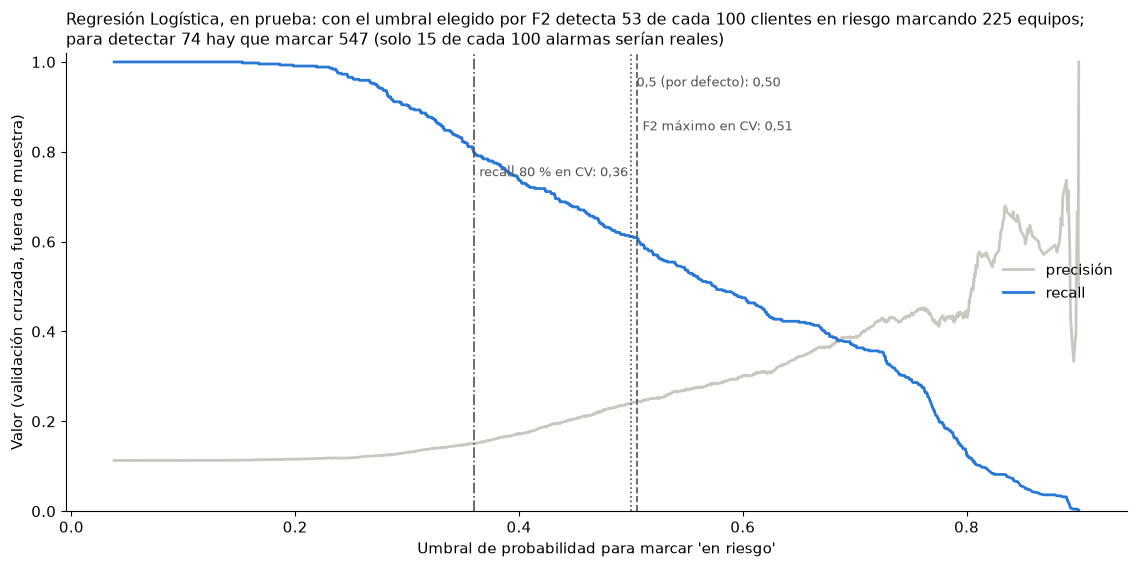

In [12]:
# Análisis del umbral del clasificador elegido.
pipe = busquedas[mejor].best_estimator_
curva_u, u_f2, comp_u, cm_u = t3.analisis_umbral(pipe, Xtr, ytr, gtr, Xte, yte)
display(comp_u.round(3))
for nombre, cm in cm_u.items():
    print(f"{nombre}: detecta {cm[1, 1]} de {cm[1].sum()} en riesgo con {cm[0, 1]} falsas alarmas")
t3.fig_umbral(curva_u, comp_u, mejor);

,variable,caida_PR_AUC_media,caida_PR_AUC_desvio
0,vec_rxp,2.653e-01,1.040e-02
1,WiFi_Tecnologia,5.000e-04,1.200e-03
2,onts_pon,4.000e-04,4.000e-04
3,Localidad,2.000e-04,9.400e-03
4,fw_generacion,1.000e-04,3.000e-04
5,fw_fuera_estandar,-2.000e-04,6.800e-03
6,Puertos_LAN,-1.200e-03,9.000e-04
7,ID,-1.400e-03,4.500e-03
8,id_rel,-2.800e-03,3.300e-03
9,Modelo_canonico,-3.500e-03,7.300e-03


,variable,coeficiente,odds_ratio
0,vec_rxp,-0.630,0.532
1,Distancia_m,0.147,1.158
2,Modelo_canonico_EG8141H5,0.135,1.145
3,Localidad_Santa Clara de Buena Vista,0.133,1.142
4,Localidad_Frontera,-0.129,0.879
5,Modelo_canonico_EG8141A5,-0.123,0.884
6,Localidad_San Martin de las Escobas,-0.114,0.892
7,Localidad_Castelar / Crispi,-0.114,0.892
8,Localidad_Bernardo de Irigoyen,0.097,1.102
9,Modelo_canonico_HG8546M,0.093,1.097


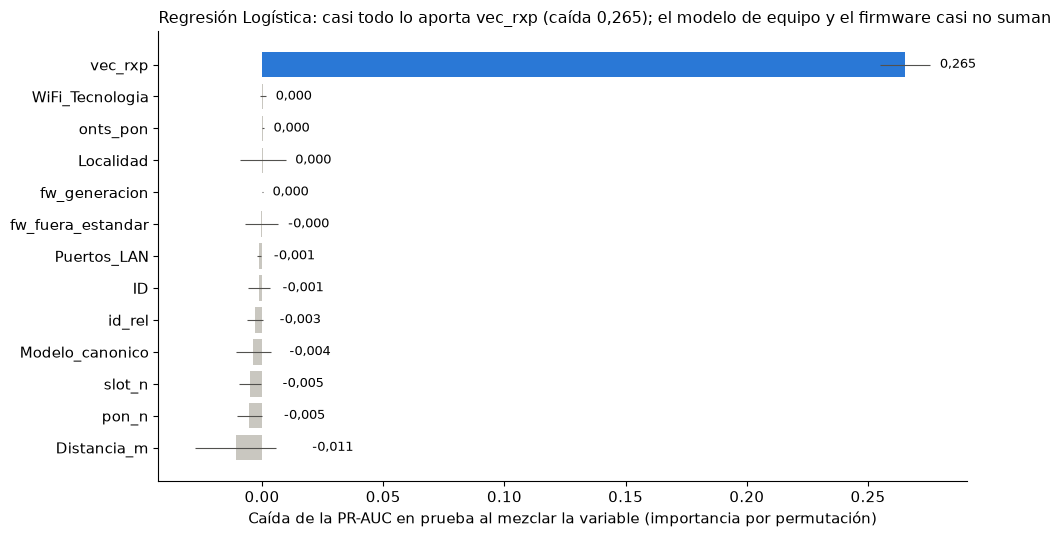

In [13]:
# Importancia por permutación (sobre la prueba, después de la evaluación final) y coeficientes de la Regresión Logística.
imp = t3.importancia(pipe, Xte, yte)
coef = t3.coeficientes_logistica(busquedas["Regresión Logística"].best_estimator_)
display(imp.round(4))
display(coef.head(10).round(3))
t3.fig_importancia(imp, mejor);

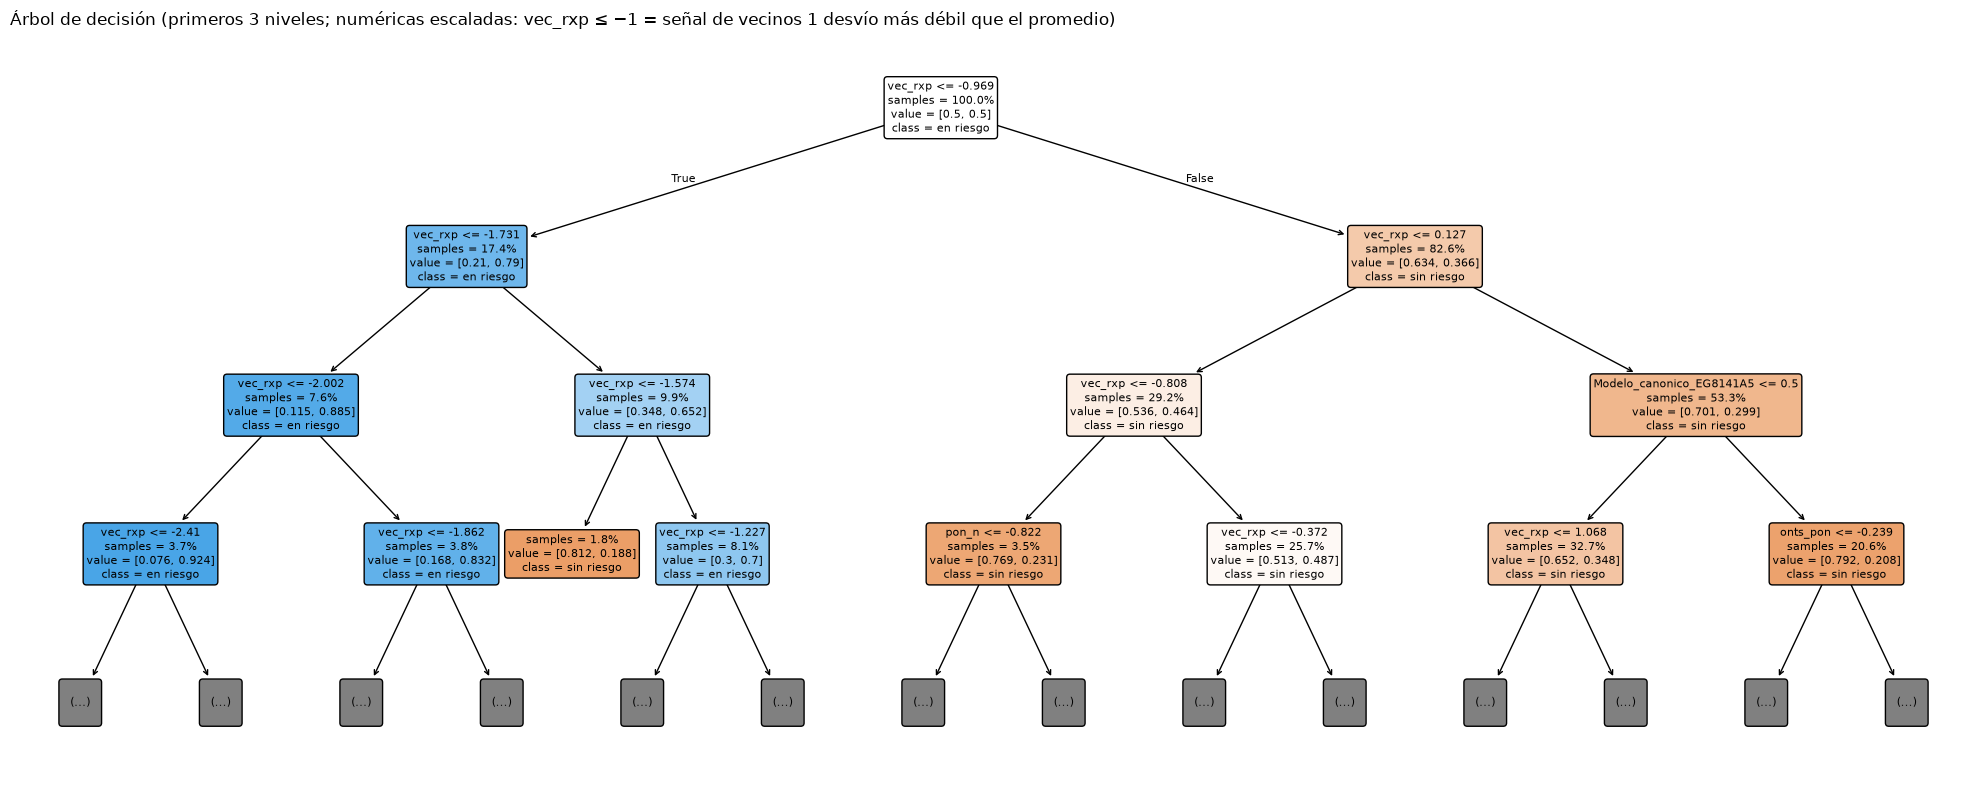

In [14]:
# Explicabilidad: el árbol de decisión dibujado (primeros niveles).
t3.fig_arbol(busquedas["Árbol de Decisión"]);

## 12. Curva de aprendizaje

PR-AUC de entrenamiento y de validación según la cantidad de equipos usados para entrenar, con la misma validación
agrupada.

In [15]:
# Curva de aprendizaje del clasificador elegido (la del Random Forest se agrega en la sección de ensamble).
curvas = {f"{mejor} (mejor)": t3.curva_aprendizaje(pipe, Xtr, ytr, gtr)}
display(curvas[f"{mejor} (mejor)"].round(3))

,n_entrenamiento,PR_AUC_entrenamiento,PR_AUC_entrenamiento_desvio,PR_AUC_validacion,PR_AUC_validacion_desvio
0,467,0.353,0.010,0.297,0.085
1,908,0.338,0.010,0.313,0.110
2,1350,0.329,0.018,0.321,0.108
3,1791,0.343,0.009,0.321,0.117
4,2233,0.343,0.014,0.322,0.116
5,2674,0.341,0.025,0.321,0.103
6,3116,0.343,0.022,0.322,0.102


## 13. Plus: ensamble

- **Random Forest** (bagging): 300 árboles que votan.
- **Gradient Boosting** (boosting): 200 árboles en secuencia.

Se entrenan con la misma partición, grilla y métricas, y se comparan contra los individuales. Preguntas: ¿mejoran? ¿a
costa de qué?

,PR-AUC CV,PR-AUC CV desvío,ROC-AUC entrenamiento,ROC-AUC prueba,PR-AUC prueba,segundos de búsqueda
Dummy (prior),0.113,0.003,0.500,0.500,0.111,0.742
Gradient Boosting,0.253,0.042,0.795,0.707,0.431,26.413
KNN,0.299,0.093,1.000,0.661,0.256,6.922
Naive Bayes,0.283,0.082,0.727,0.670,0.280,1.332
Random Forest,0.342,0.147,0.919,0.675,0.314,27.654
Regla de los vecinos,NaN,NaN,0.732,0.710,0.397,NaN
Regresión Logística,0.322,0.114,0.741,0.698,0.389,3.260
Árbol de Decisión,0.301,0.129,0.838,0.710,0.397,3.702


,modelo,ROC_entrenamiento,ROC_cv,ROC_prueba,brecha_entrenamiento_cv,brecha_entrenamiento_prueba,diagnostico
0,Dummy (prior),0.500,0.500,0.500,0.000,0.000,subajuste: sesgo alto (no separa ni el entrena...
1,Regresión Logística,0.741,0.718,0.698,0.023,0.043,ajuste razonable: sesgo y varianza equilibrados
2,Árbol de Decisión,0.838,0.669,0.710,0.169,0.128,sobreajuste: varianza alta (memoriza el entren...
3,KNN,1.000,0.688,0.661,0.312,0.339,sobreajuste: varianza alta (memoriza el entren...
4,Naive Bayes,0.727,0.707,0.670,0.020,0.056,ajuste razonable: sesgo y varianza equilibrados
5,Random Forest,0.919,0.711,0.675,0.209,0.244,sobreajuste: varianza alta (memoriza el entren...
6,Gradient Boosting,0.795,0.663,0.707,0.132,0.088,sobreajuste: varianza alta (memoriza el entren...


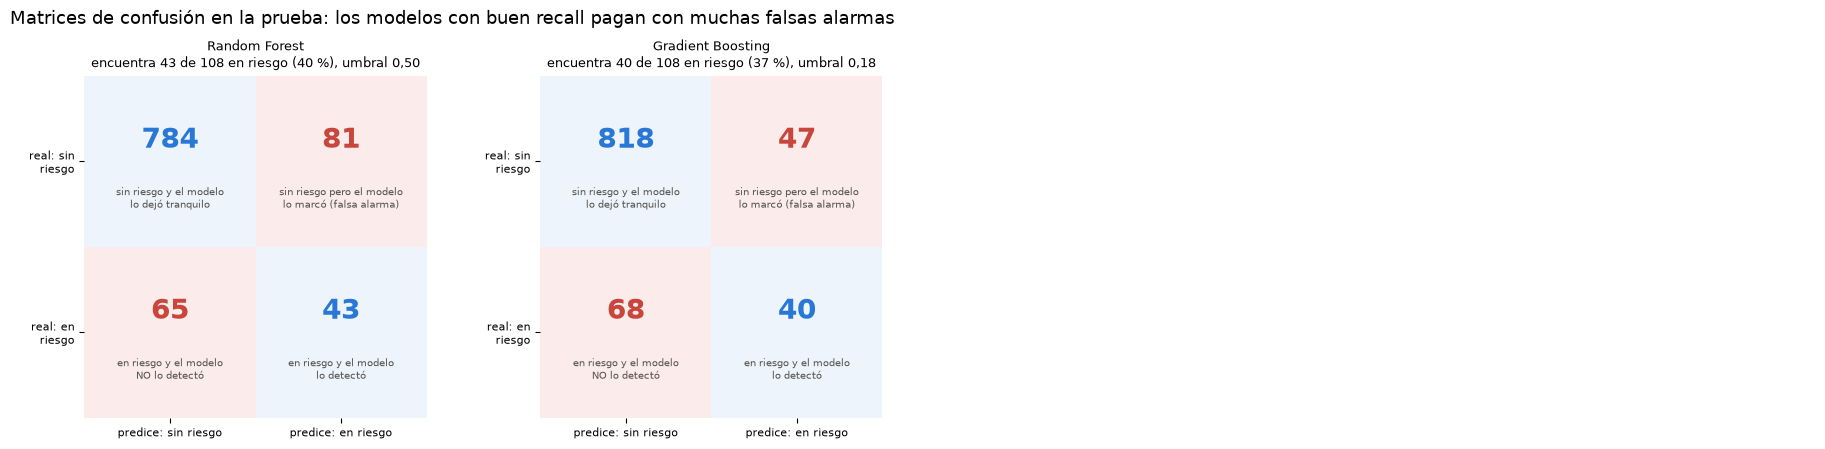

In [16]:
# Entrenamiento de los ensambles y tabla completa.
busq_ens = {n: t3.entrenar(n, Xtr, ytr, gtr) for n in t3.ENSAMBLES}
busquedas.update(busq_ens)
tabla = t3.ordenar(pd.concat([tabla_ind, t3.tabla_metricas(busq_ens, Xtr, ytr, gtr, Xte, yte)]))
diag = t3.diagnostico(tabla).dropna()
reportes, matrices = t3.reportes_y_matrices(busquedas, Xtr, ytr, Xte, yte)
espacio, mejora = t3.mejora_gridsearch(busquedas)
comp = pd.DataFrame({"PR-AUC CV": t3.pivote(tabla, "PR_AUC")["validación cruzada (media)"],
                     "PR-AUC CV desvío": t3.pivote(tabla, "PR_AUC")["validación cruzada (desvío)"],
                     "ROC-AUC entrenamiento": t3.pivote(tabla, "ROC_AUC")["entrenamiento"],
                     "ROC-AUC prueba": t3.pivote(tabla, "ROC_AUC")["prueba"], "PR-AUC prueba": t3.pivote(tabla, "PR_AUC")["prueba"],
                     "segundos de búsqueda": pd.Series({n: gs.segundos_ for n, gs in busquedas.items()})})
display(comp.round(3))
display(diag.round(3))
t3.fig_matrices(matrices, t3.ENSAMBLES, {n: gs.umbral_ for n, gs in busquedas.items()});

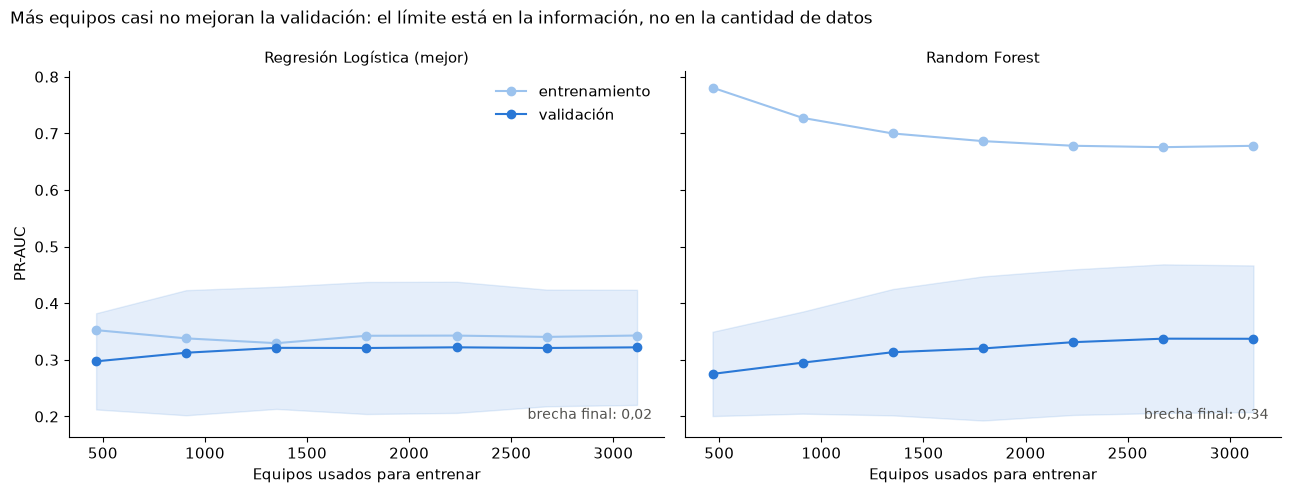

In [17]:
# Curva de aprendizaje del Random Forest, para comparar con la del clasificador elegido.
if mejor != "Random Forest":
    curvas["Random Forest"] = t3.curva_aprendizaje(busquedas["Random Forest"].best_estimator_, Xtr, ytr, gtr)
t3.fig_curva_aprendizaje(curvas);

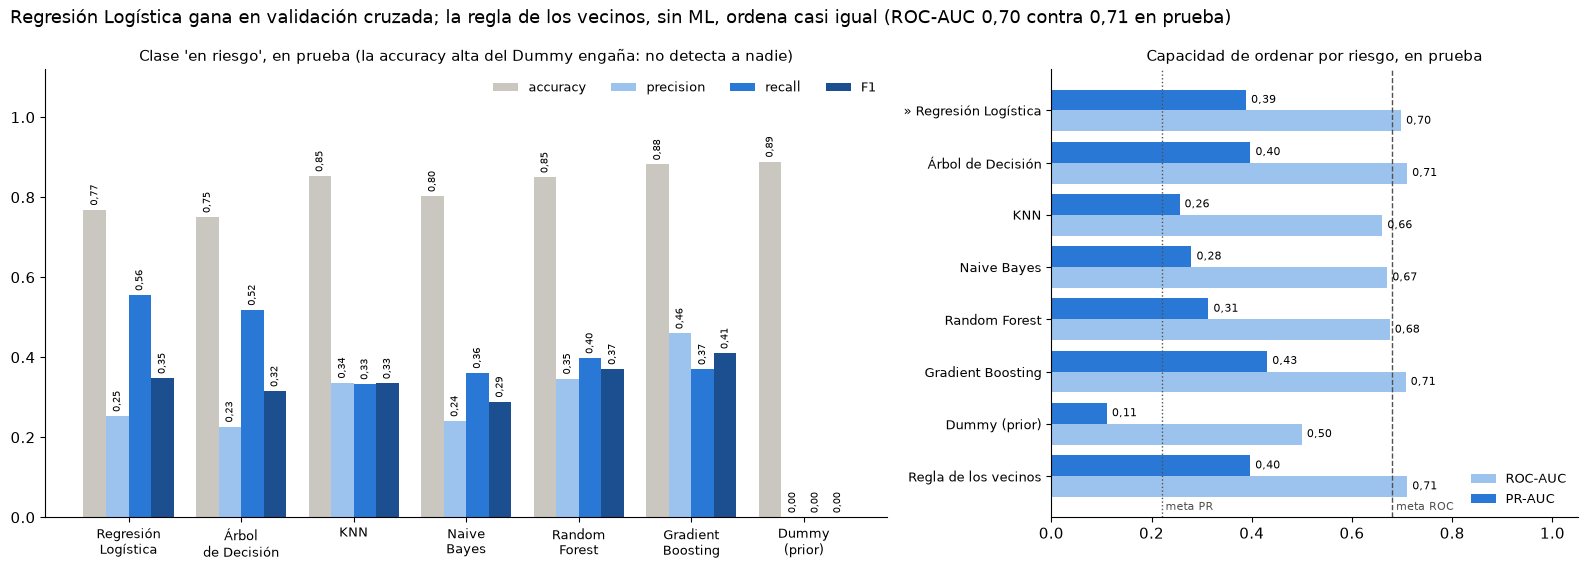

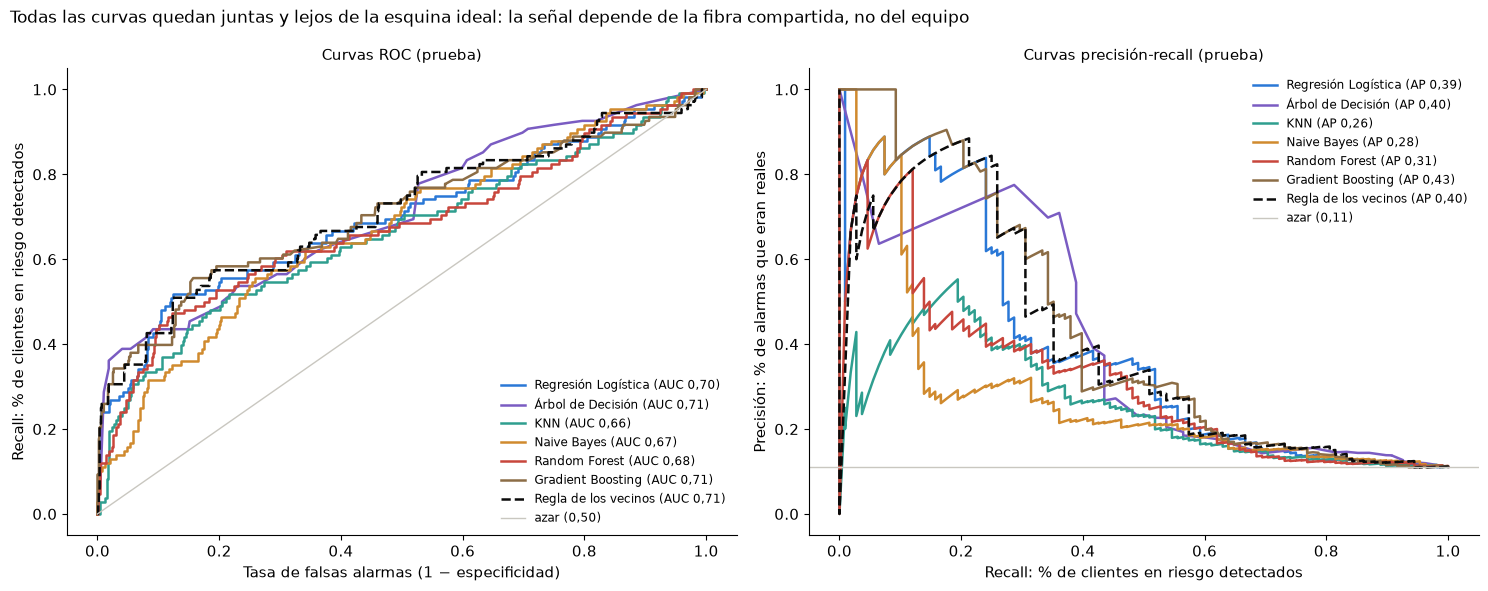

In [18]:
# Gráficos comparativos de todos los modelos: métricas en prueba y curvas ROC / precisión-recall.
t3.fig_comparacion(tabla, mejor);
t3.fig_curvas(busquedas, Xte, yte, test);

## 14. Plus: clustering

K-Means con las mismas variables (one-hot + escaladas), **sin la etiqueta**, sobre los 4872 equipos (no hay etiqueta
que pueda filtrarse).
- **k:** de 2 a 8, elegido por silueta, mirando también el codo y Davies-Bouldin.
- **Comparación con la clase real:** % en riesgo por grupo y `adjusted_rand_score` (ARI: 0 = azar, 1 = coincidencia total).
- **Visualización:** PCA en 2D, coloreado por grupo y por clase real.

,k,inercia,silueta,davies_bouldin,ARI
0,2,46059.368,0.244,2.117,0.157
1,3,41381.856,0.217,1.853,0.099
2,4,37427.204,0.158,1.915,0.035
3,5,34412.076,0.172,1.802,0.037
4,6,32148.867,0.150,1.898,0.020
5,7,30615.036,0.167,1.683,0.022
6,8,28809.214,0.154,1.663,0.013


Mejor k por silueta: 2


,grupo,equipos,en_riesgo,pct_en_riesgo,vec_rxp_media,distancia_mediana_m,localidad_principal,pct_localidad_principal,modelo_principal
0,0,853,224,0.263,-23.228,8006.0,Bernardo de Irigoyen,0.469,EG8141A5
1,1,4019,324,0.081,-20.233,1406.0,San Vicente,0.306,EG8141A5


Con k = 4:


,grupo,equipos,en_riesgo,pct_en_riesgo,vec_rxp_media,distancia_mediana_m,localidad_principal,pct_localidad_principal,modelo_principal
0,0,553,62,0.112,-21.196,1528.0,Frontera,0.374,EG8143A5
1,1,675,180,0.267,-23.335,8206.0,Bernardo de Irigoyen,0.516,EG8141A5
2,2,1100,84,0.076,-20.283,1441.0,San Vicente,0.311,EG8141A5
3,3,2544,222,0.087,-20.183,1391.5,San Vicente,0.344,EG8141A5


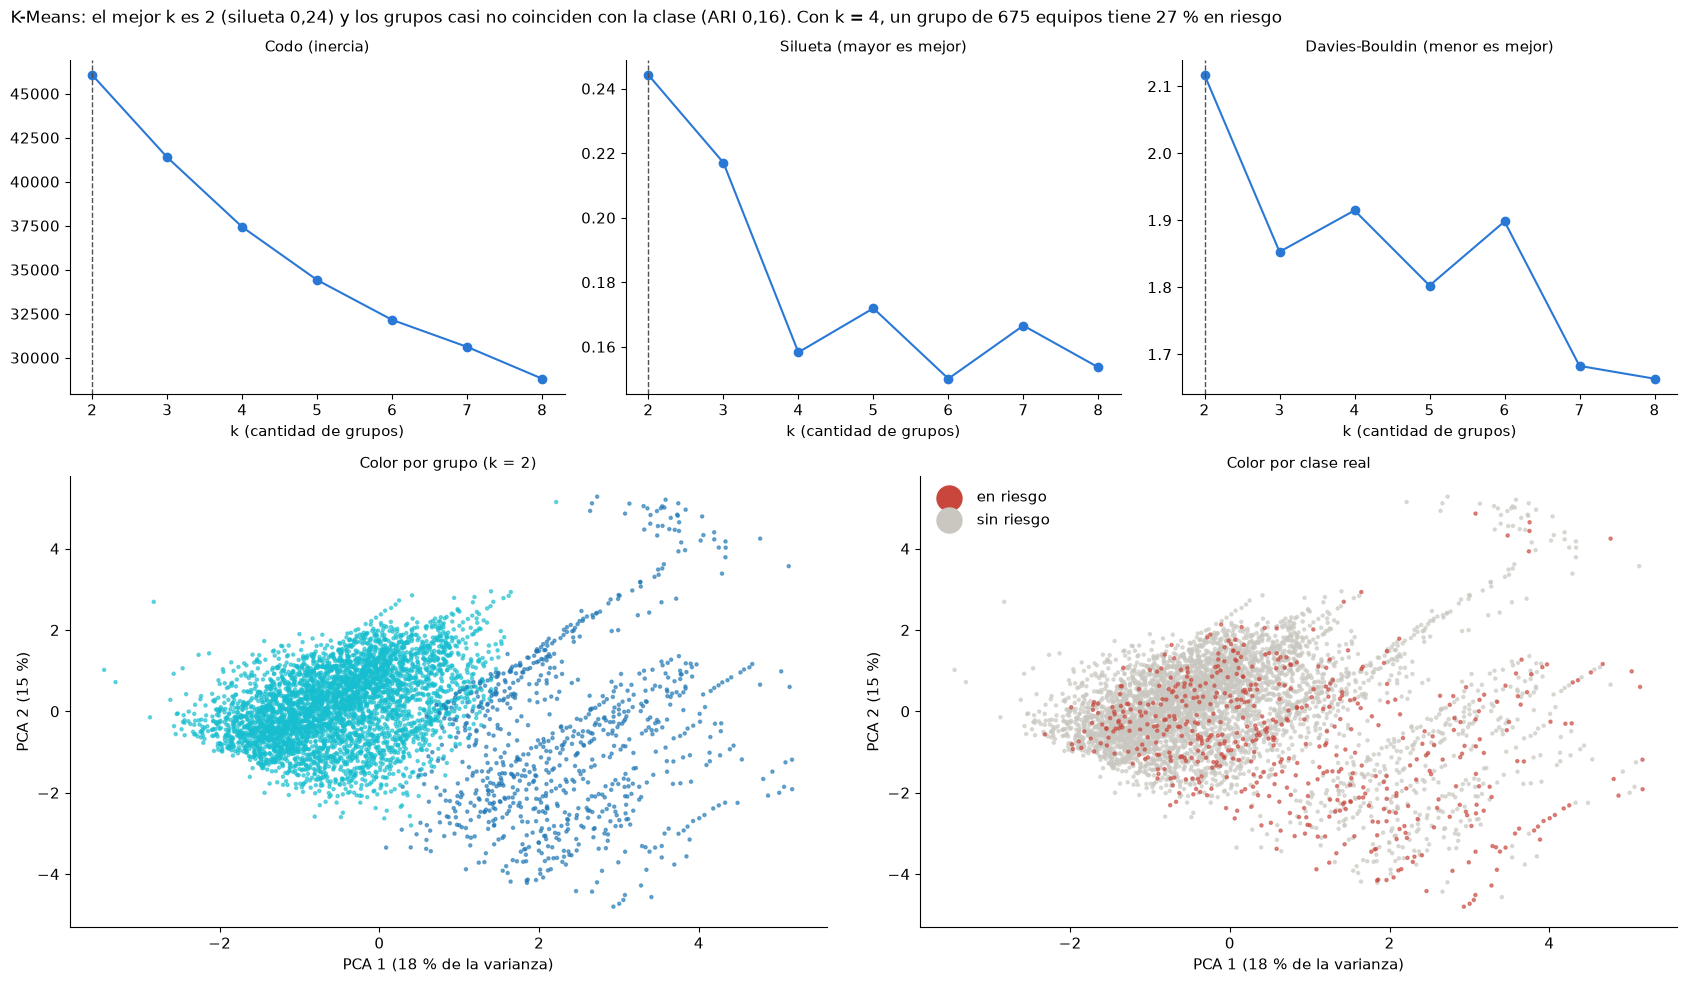

In [19]:
# Selección de k, perfil de los grupos y gráficos.
cl = t3.clustering(d)
display(cl["seleccion"].round(3))
print(f"Mejor k por silueta: {cl['k_mejor']}")
display(cl["perfil_mejor"].round(3))
print(f"Con k = {cl['k_extra']}:")
display(cl["perfil_extra"].round(3))
t3.fig_clustering(cl, d);

## 15. Criterio SMART (objetivo 14)

Sobre el clasificador elegido, en prueba: **ROC-AUC ≥ 0,68** y **PR-AUC ≥ 0,22** (el doble de la tasa base). Como
control, también se muestra qué pasaría con el modelo que se elegiría entre **todos** (incluidos los ensambles) por
validación cruzada.

In [20]:
# Evaluación del criterio SMART.
smart = t3.criterio_smart(tabla, mejor)
display(smart.round(3))
print("Clasificador elegido cumple todo:", bool(smart[smart["rol"] == "elegido (individual)"]["cumple"].all()))

,modelo,rol,criterio,umbral,valor,cumple
0,Regresión Logística,elegido (individual),ROC-AUC en prueba,>= 0.68,0.698,True
1,Regresión Logística,elegido (individual),PR-AUC en prueba,>= 0.22,0.389,True
2,Random Forest,mejor en CV entre todos,ROC-AUC en prueba,>= 0.68,0.675,False
3,Random Forest,mejor en CV entre todos,PR-AUC en prueba,>= 0.22,0.314,True


Clasificador elegido cumple todo: True


## 16. Guardar resultados y borradores

In [21]:
# Guardado: mismo diccionario de resultados que arma t3.correr() desde run_all.py.
r = dict(d=d, train=train, test=test, cols=cols, Xtr=Xtr, ytr=ytr, gtr=gtr, Xte=Xte, yte=yte, busquedas=busquedas,
         vecinos=vecinos, tabla=tabla, diag=t3.diagnostico(tabla), mejor=mejor, reportes=reportes, matrices=matrices,
         espacio=espacio, mejora=mejora, curva_u=curva_u, u_f2=u_f2, comp_u=comp_u, cm_u=cm_u, imp=imp, coef=coef,
         curvas=curvas, cl=cl, smart=smart)
t3.guardar_todo(r)
from tp3_informe import escribir
for ruta in escribir():
    print("Borrador:", ruta.relative_to(RAIZ))

Borrador: reports\TP3\informe_borrador.md
Borrador: reports\TP3\cuestionario_borrador.md


## 17. Conclusiones

Las cifras salen de la celda de abajo. Las respuestas al cuestionario están en `reports/TP3/cuestionario_borrador.md`.

In [22]:
# Resumen final con las cifras obtenidas.
p = lambda met: t3.pivote(tabla, met)["prueba"]
cv = t3.pivote(tabla, "PR_AUC")["validación cruzada (media)"]
cm = matrices[(mejor, "prueba")]
print(f"1. Elegido: {mejor}. En prueba ROC-AUC {p('ROC_AUC')[mejor]:.3f}, PR-AUC {p('PR_AUC')[mejor]:.3f} "
      f"(azar {yte.mean():.3f}); detecta {cm[1, 1]} de {cm[1].sum()} clientes en riesgo con {cm[0, 1]} falsas alarmas.")
print(f"2. La regla de los vecinos, sin ML: ROC-AUC {p('ROC_AUC')['Regla de los vecinos']:.3f}, PR-AUC {p('PR_AUC')['Regla de los vecinos']:.3f}. "
      f"La señal depende de la fibra compartida del puerto.")
dg = t3.diagnostico(tabla).set_index("modelo")
print(f"3. Ensambles: PR-AUC CV Random Forest {cv['Random Forest']:.3f} ± {t3.pivote(tabla, 'PR_AUC')['validación cruzada (desvío)']['Random Forest']:.3f} "
      f"y Gradient Boosting {cv['Gradient Boosting']:.3f}, contra {cv[mejor]:.3f} del elegido.")
for n in t3.ENSAMBLES:
    print(f"   - {n}: {dg.loc[n, 'diagnostico'].split(':')[0]}; ROC-AUC de prueba {p('ROC_AUC')[n]:.3f} "
          f"({'mayor' if p('ROC_AUC')[n] > p('ROC_AUC')[mejor] else 'menor'} que {p('ROC_AUC')[mejor]:.3f}).")
pe = cl["perfil_extra"]; top = pe.loc[pe["pct_en_riesgo"].idxmax()]
print(f"4. Clustering: mejor k = {cl['k_mejor']} (ARI {cl['seleccion'].set_index('k').loc[cl['k_mejor'], 'ARI']:.2f}); "
      f"con k = {cl['k_extra']}, un grupo de {int(top['equipos'])} equipos con {top['pct_en_riesgo']:.0%} en riesgo.")
print(f"5. Criterio SMART del elegido: {'se cumple' if smart[smart['rol'] == 'elegido (individual)']['cumple'].all() else 'NO se cumple'}.")

1. Elegido: Regresión Logística. En prueba ROC-AUC 0.698, PR-AUC 0.389 (azar 0.111); detecta 60 de 108 clientes en riesgo con 177 falsas alarmas.
2. La regla de los vecinos, sin ML: ROC-AUC 0.710, PR-AUC 0.397. La señal depende de la fibra compartida del puerto.
3. Ensambles: PR-AUC CV Random Forest 0.342 ± 0.147 y Gradient Boosting 0.253, contra 0.322 del elegido.
   - Random Forest: sobreajuste; ROC-AUC de prueba 0.675 (menor que 0.698).
   - Gradient Boosting: sobreajuste; ROC-AUC de prueba 0.707 (mayor que 0.698).
4. Clustering: mejor k = 2 (ARI 0.16); con k = 4, un grupo de 675 equipos con 27% en riesgo.
5. Criterio SMART del elegido: se cumple.
